In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating the network

In [4]:
N = 1024
m = 2
k = 5

In [5]:
P = np.array([[0.59, 0.43], [0.43, 0.78]])
l = np.array([0.25, 0.75])

In [6]:
generator = MultifractalNetworkGenerator(P,l,k,N,num_workers=-1)

Initializing...
0.0008721351623535156


In [45]:
generator()
print(2 * generator.G.number_of_edges() / generator.G.number_of_nodes())

Initializing...
0.001005411148071289
Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 138.17it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 77.80it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 77.13it/s]

... (27 outputs left out)


100%|██████████| 32/32 [00:00<00:00, 74.73it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 73.58it/s]

111.177734375


Calculating betweenness...
Done.
Calculating node positions...
Done.


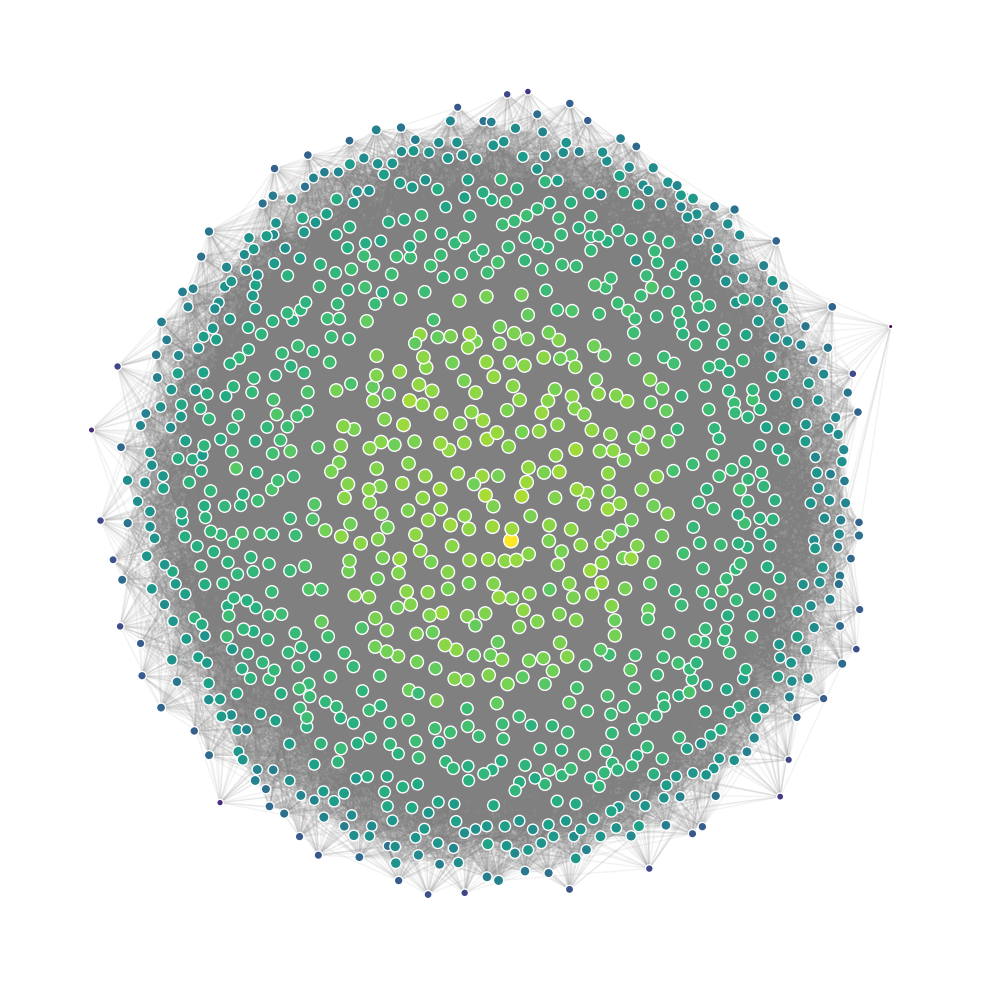

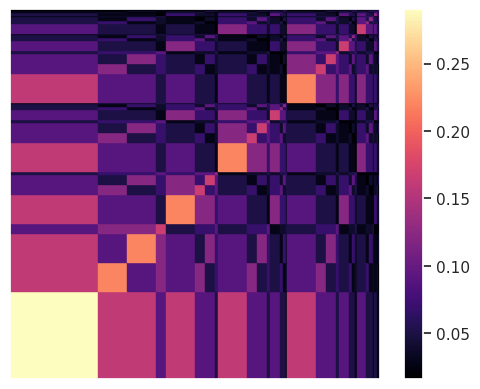

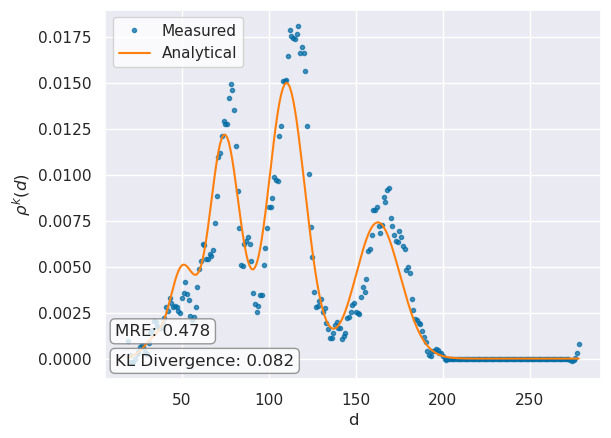

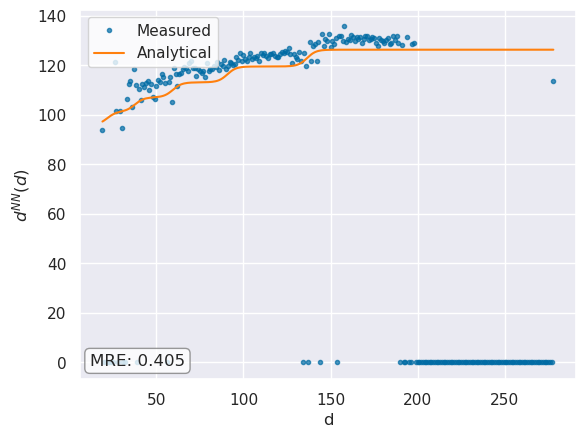

Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:20.121618
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:54:20.038351


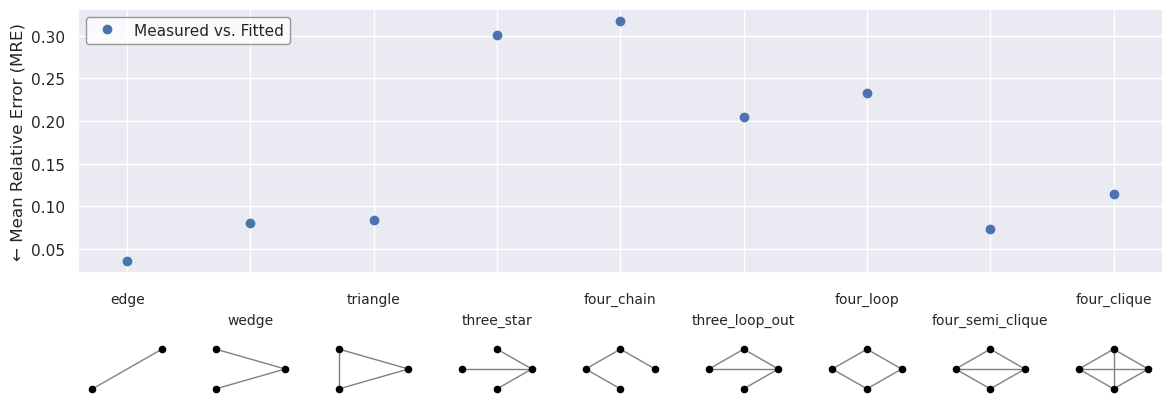

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'analytical_count': 54880.31575659009,
  'count': 56923,
  'MRE': 0.03588504195860916},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'analytical_count': 6580710.350378295,
  'count': 6052444,
  'MRE': 0.08027497371129969},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'analytical_count': 304876.6618656895,
  'count': 332737,
  'MRE': 0.08373080881991032},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'analytical_count': 286657978.81376827,
  'count': 200435629,
  'MRE': 0.3007847546074548},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'analytical_count': 799355175.2904582,
  'count': 545864993,


In [9]:
generator.plot_generated_network(
    layout_func = nx.kamada_kawai_layout,
    largest_component_only = False,
)

generator.network_stats(
    filename = "figures/synthetic_network_1k_plot_ground_truth.pdf",
    motif_analyzer_args = {
        'exact': True,
        'bootstrap_iters': None,
        'ci': None
    }
)

generator.motifs

In [47]:
generator.save_network('./test_networks/synthetic_network_1k.graphml')

# Fitting

## Load, count motifs

In [4]:
filename = './test_networks/synthetic_network_1k.graphml'
G = nx.read_graphml(filename)

In [5]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size**2))+1)

2  k_max:  6
3  k_max:  4
5  k_max:  3
6  k_max:  2
7  k_max:  2


In [6]:
mfnf = MultifractalNetworkFitter(G,
                                 d_range = [1,200],
                                 motifs = [
                                     {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
                                     {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
                                     {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
                                     {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
                                 ],
                                 sampling_ratios = {3: None,
                                                    4: None},
                                 motif_analyzer_args={'exact': True, 'bootstrap_iters': None, 'ci': None},
                                 population_size = 100,
                                 weights = {'rho':9,
                                            'deg_nn':9,
                                            'motifs':1,
                                            'edge':9},
                                 pre_loaded_motifs = './test_networks/synthetic_network_1k_motifs.pkl'
                                )

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Succesfully loaded motifs for network G from ./test_networks/synthetic_network_1k_motifs.pkl


In [7]:
P = np.array([[0.59, 0.43], [0.43, 0.78]])
l = np.array([0.25, 0.75])
k = 5
mfnf.set_ground_truth(P = P, l = l, k = k)

In [64]:
mfnf.save_motifs('./test_networks/synthetic_network_1k_motifs.pkl')

## Grid Search - Find m,k,P,l together

In [8]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,   'k': [1,6]},
                {'m': 3,   'k': [1,4]},
               ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-19 12:08:05,323] A new study created in memory with name: no-name-09f7fb57-6c35-40ab-a0c1-aa9a82a42f25


Grid Search requires 5 trials...


[I 2025-02-19 12:08:12,753] Trial 0 finished with value: 2.5856655703745695 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 2.5856655703745695.
[I 2025-02-19 12:08:20,268] Trial 1 finished with value: 21.780631136735 and parameters: {'m': 2, 'k': 1}. Best is trial 0 with value: 2.5856655703745695.
[I 2025-02-19 12:08:27,536] Trial 2 finished with value: 5.255297067116675 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 2.5856655703745695.
[I 2025-02-19 12:08:34,866] Trial 3 finished with value: 2.302384259036228 and parameters: {'m': 2, 'k': 4}. Best is trial 3 with value: 2.302384259036228.
[I 2025-02-19 12:08:43,488] Trial 4 finished with value: 2.4072245613786003 and parameters: {'m': 2, 'k': 5}. Best is trial 3 with value: 2.302384259036228.
[I 2025-02-19 12:08:43,489] A new study created in memory with name: no-name-51409db0-5da9-4dde-bb05-c887c99fc49f


Grid Search requires 3 trials...


[I 2025-02-19 12:08:58,113] Trial 0 finished with value: 2.544073962140393 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 2.544073962140393.
[I 2025-02-19 12:09:15,004] Trial 1 finished with value: 2.6688648471758576 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 2.544073962140393.
[I 2025-02-19 12:09:32,918] Trial 2 finished with value: 5.46942838151102 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 2.544073962140393.


Best parameters:  {'m': 2, 'k': 4}
Best energy:  4.67469322492543
Best KL-divergence:  0.041799017767905046
Best KLD augumented energy: 2.302384259036228
Best P matrix:
 [[0.72734175 0.41356116]
 [0.41356116 0.43781849]]
Best l vector:
 [0.70750361 0.29249639]


Energy: 4.7075094029656706
KL-divergence: 0.038081166063807244
KLD augumented energy: 2.2793658646436437
[[0.73390715 0.4144568 ]
 [0.4144568  0.43699221]]
[0.69781014 0.30218986]


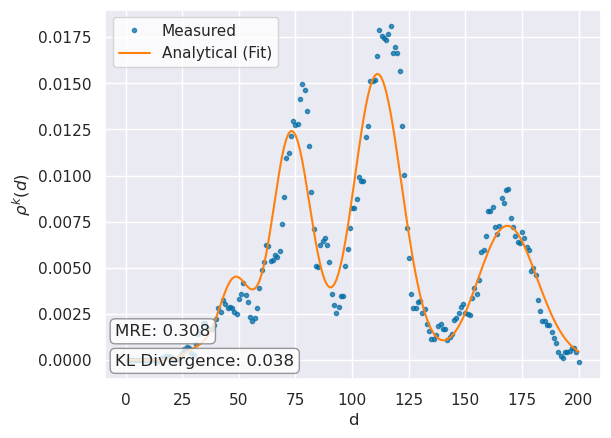

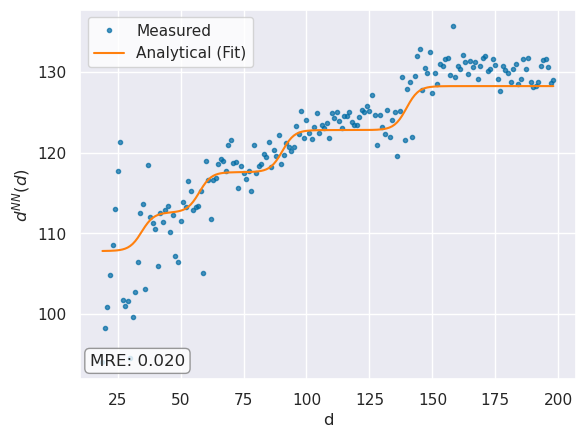

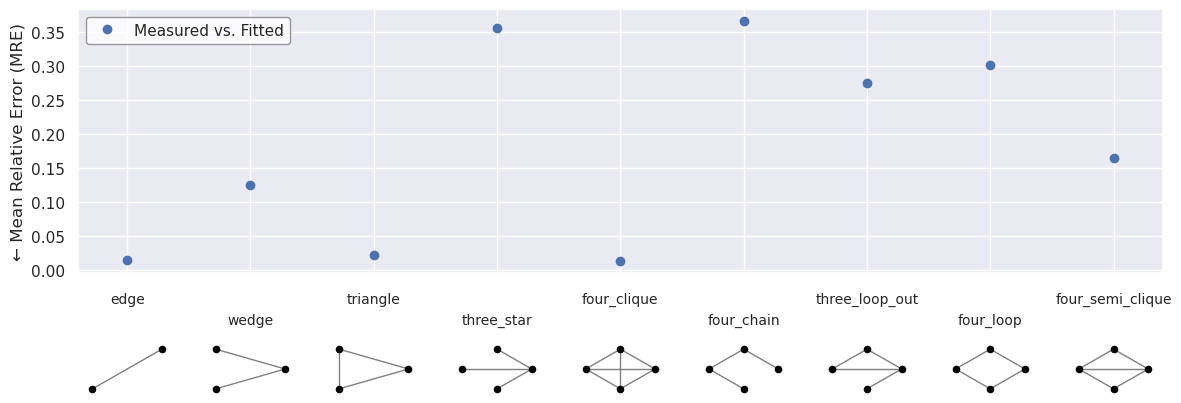

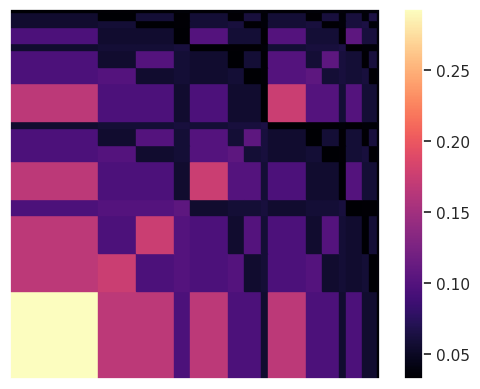

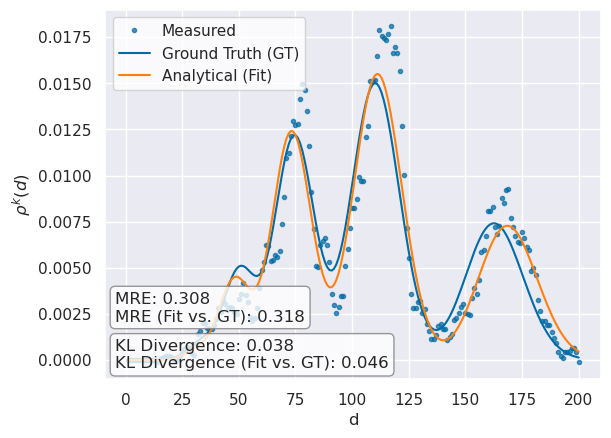

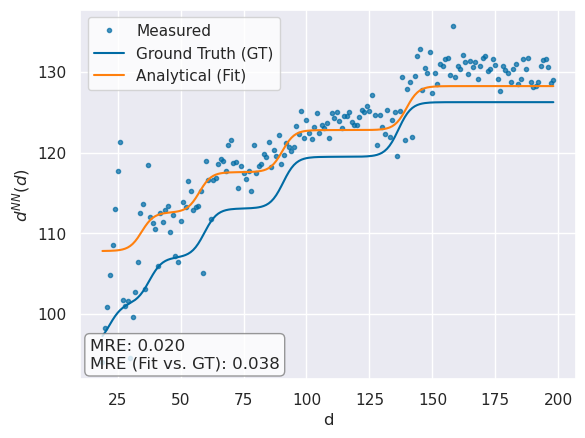

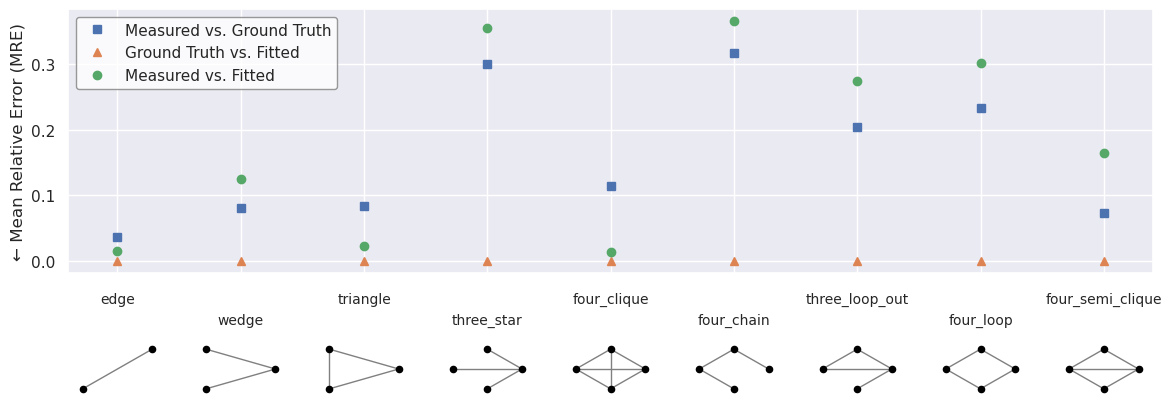

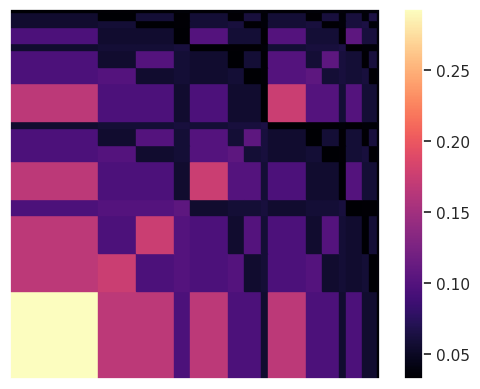

In [9]:
M = 2
K = 4
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False
)

---

In [14]:
import pickle
with open('./test_networks/synthetic_network_1k_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

## Comparing the m-k combinations that are close to 2-4 (best)

### 2-4

Energy: 4.621925781627021
KL-divergence: 0.035266756182963606
KLD augumented energy: 2.1967978548482505
[[0.73257327 0.40015902]
 [0.40015902 0.48442936]]
[0.70585901 0.29414099]


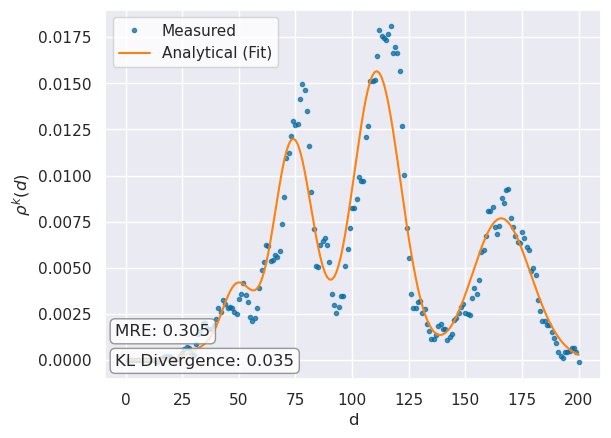

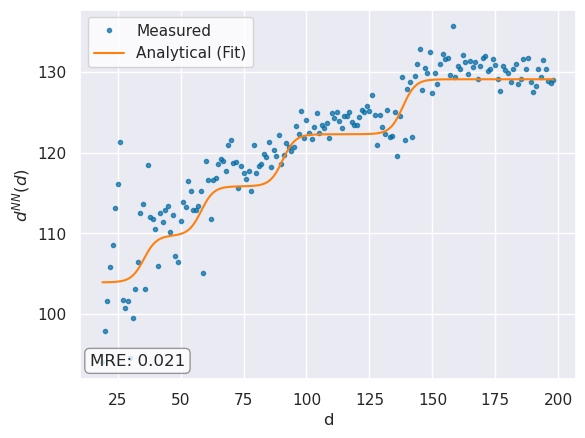

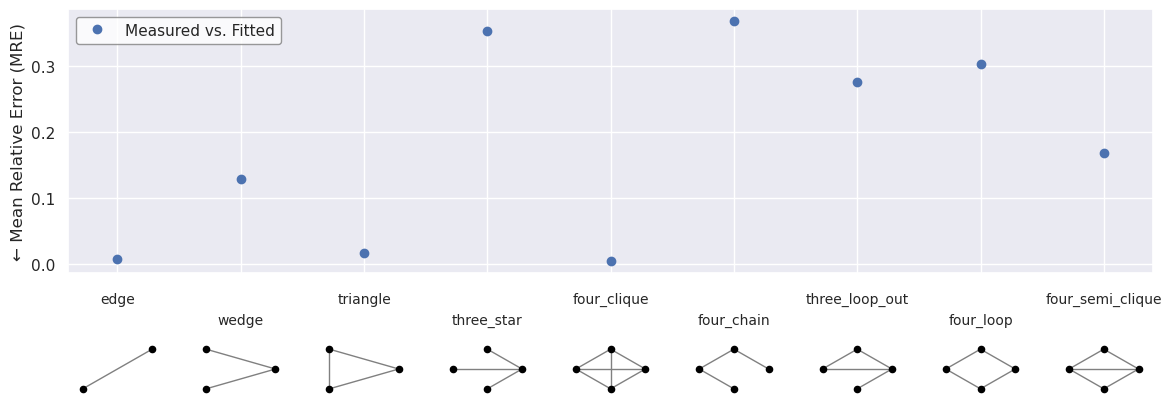

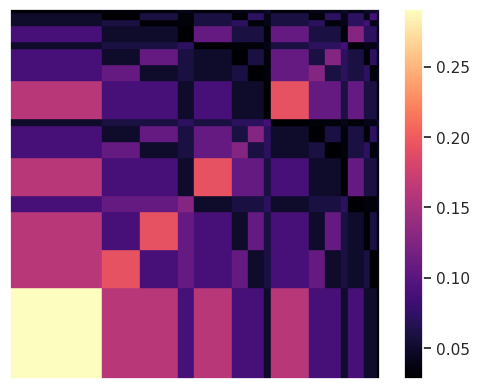

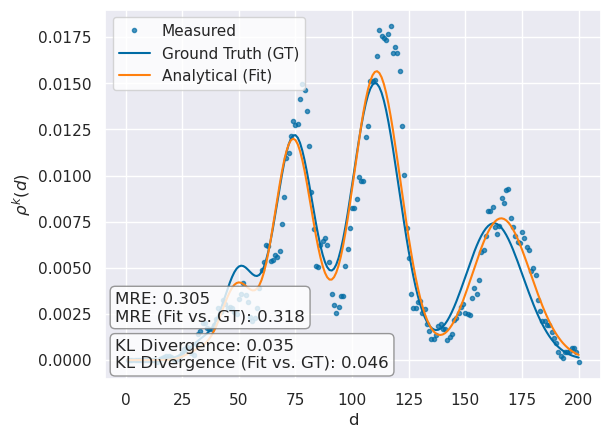

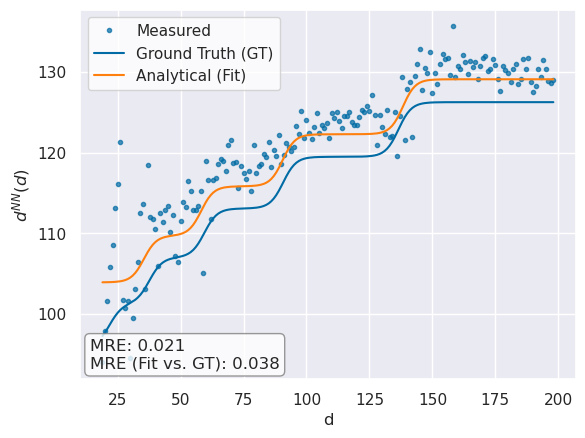

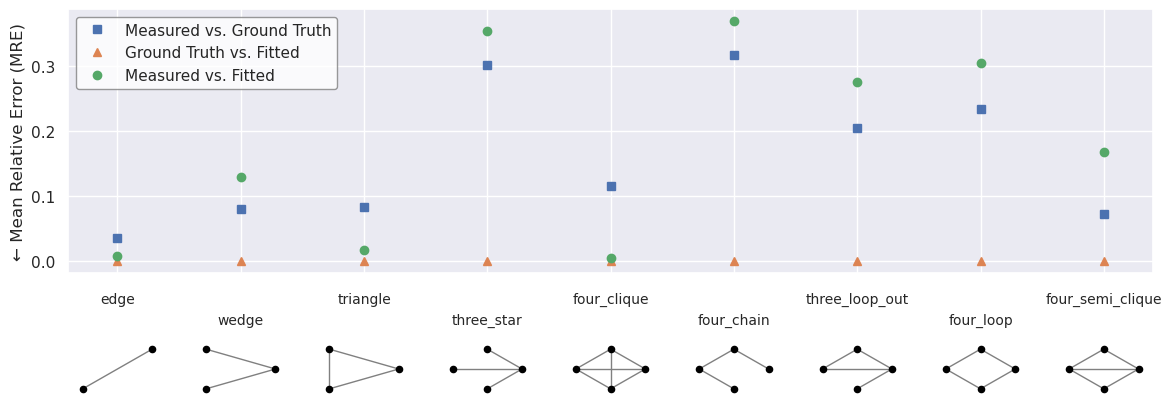

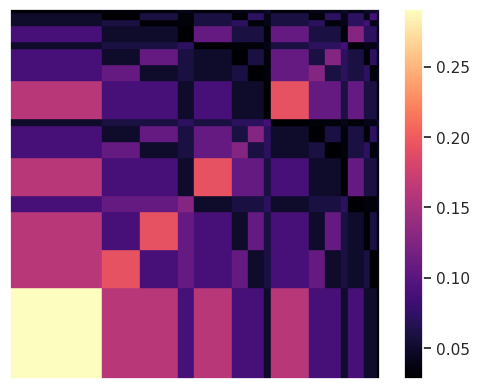

In [11]:
M = 2
K = 4
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_4.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_4_gt.pdf"
)

##### Bootstrapping

In [29]:
M = 2
K = 4
mfnf.find_P_l(m = M, k = K, one_shot=True)
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'median'
)

Energy: 4.711615828618358
KL-divergence: 0.03345737290088537
KLD augumented energy: 2.2753679016350374
Gathering statistics (300 runs)...


100%|██████████| 300/300 [44:13<00:00,  8.84s/it]

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:01.311993
Energy = 4.69 (4.61, 4.86)
l = [0.70 (0.68, 0.72), 0.30 (0.28, 0.32)]
P = [
[0.73 (0.72, 0.74), 0.41 (0.39, 0.44)],

[0.41 (0.39, 0.44), 0.46 (0.39, 0.51)]
]


In [30]:
with open('./test_networks/synthetic_network_1k_2_4_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

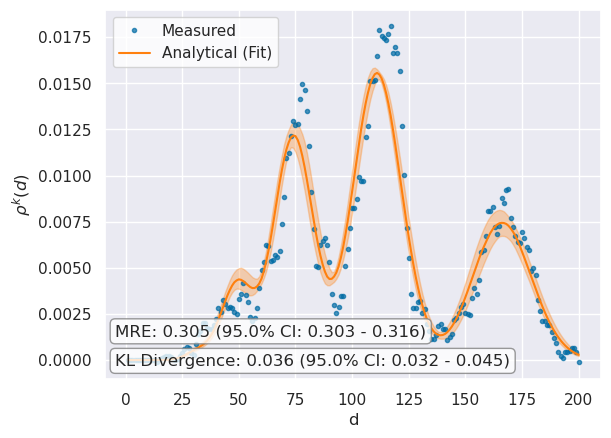

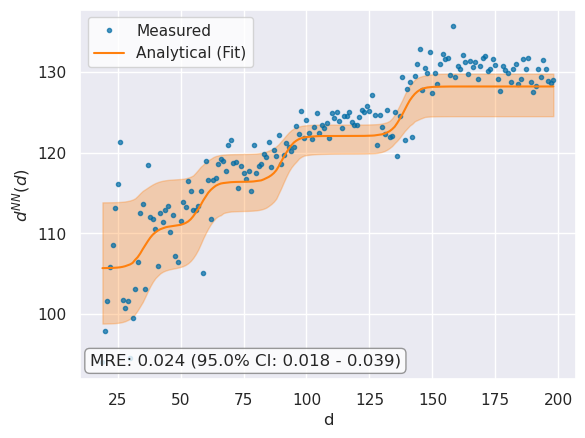

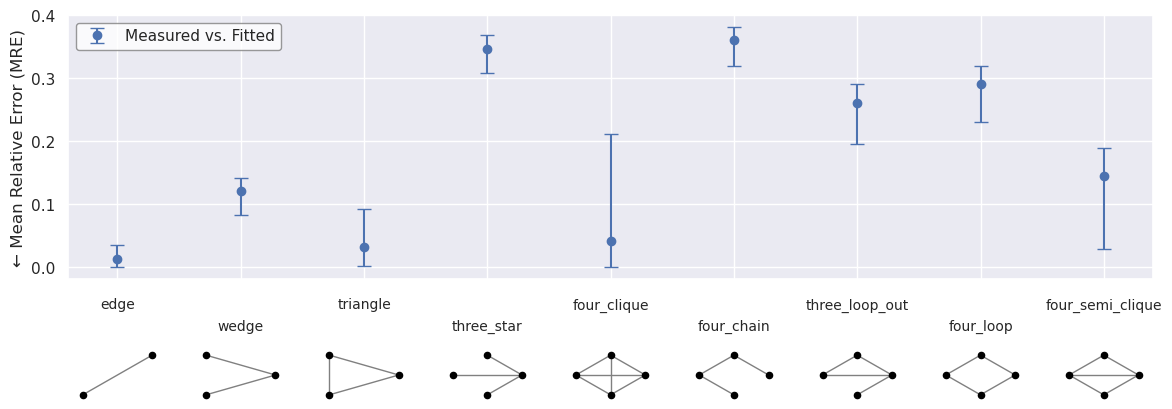

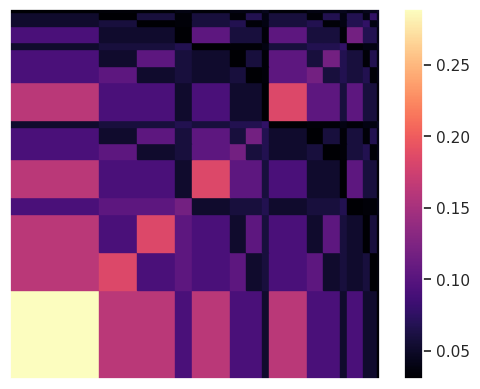

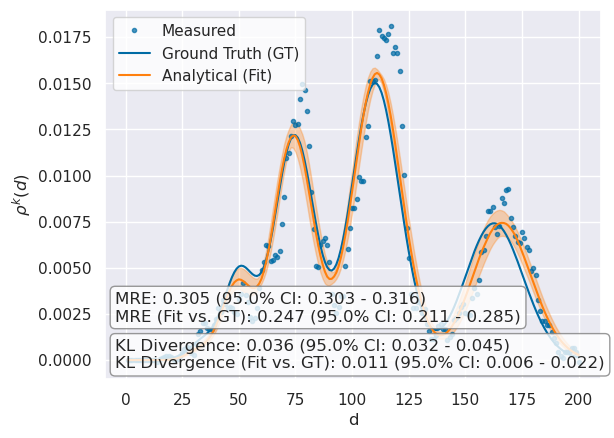

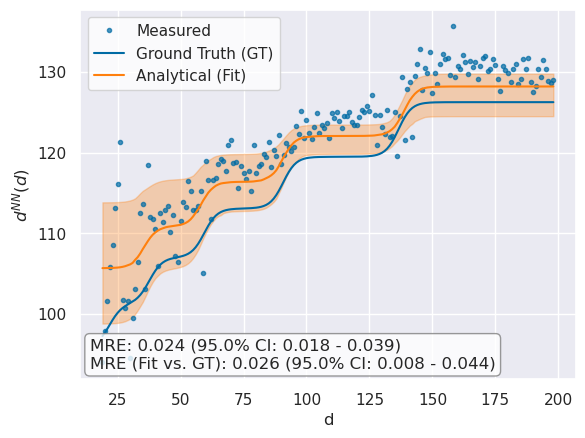

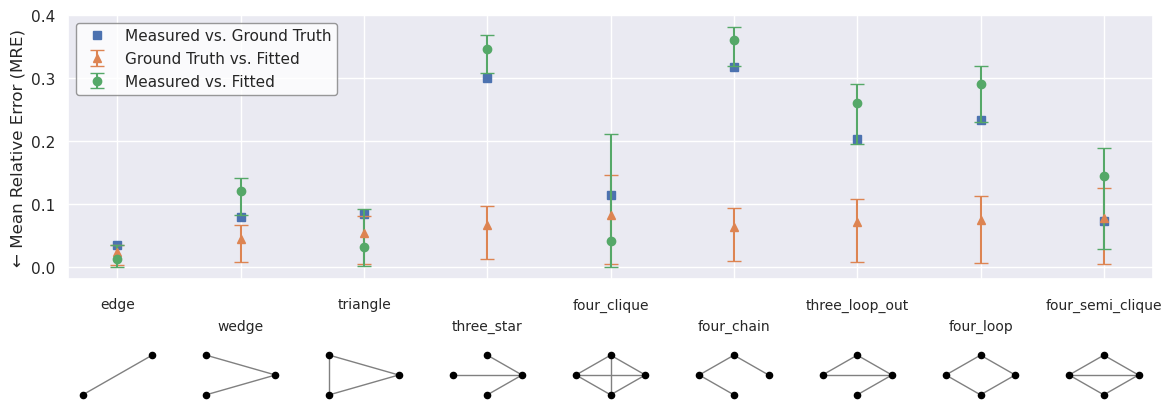

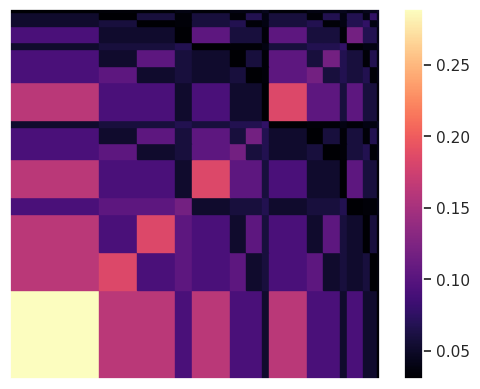

In [31]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_4_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_4_bootstrap_gt.pdf"
)

### 3-3

Energy: 4.535551327712405
KL-divergence: 0.03200602117280026
KLD augumented energy: 2.2876850331745584
[[0.67233076 0.3742616  0.11436342]
 [0.3742616  0.36980582 0.29037615]
 [0.11436342 0.29037615 0.26565867]]
[0.59318599 0.3924734  0.01434062]


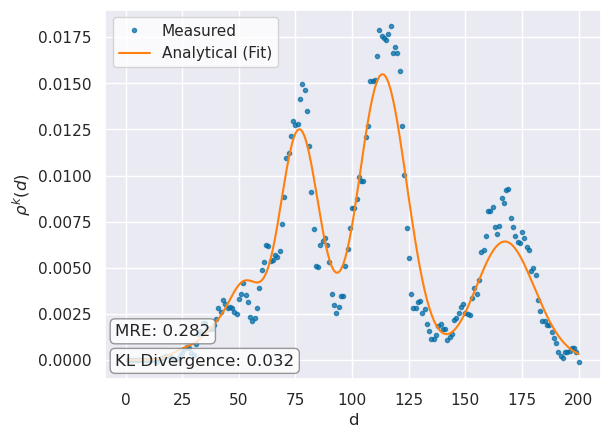

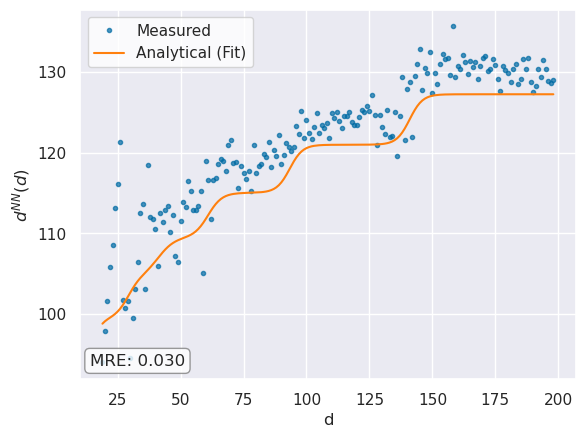

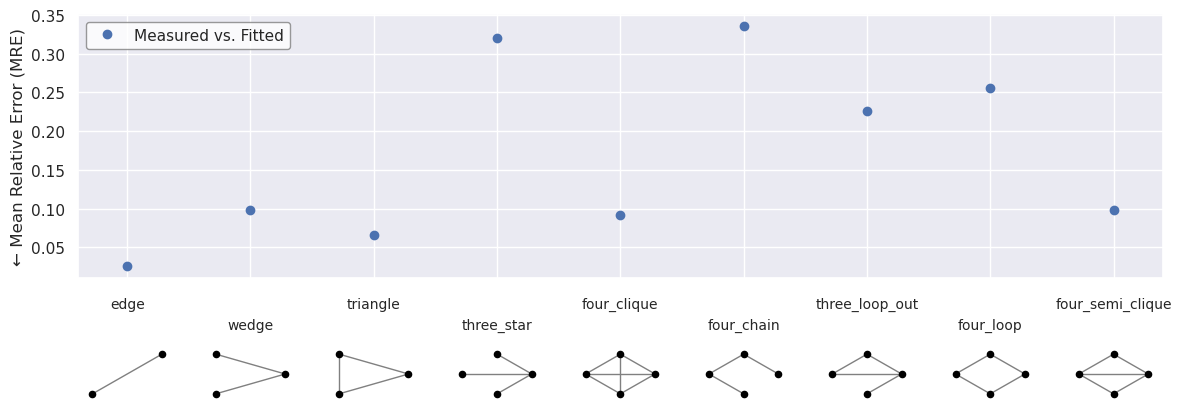

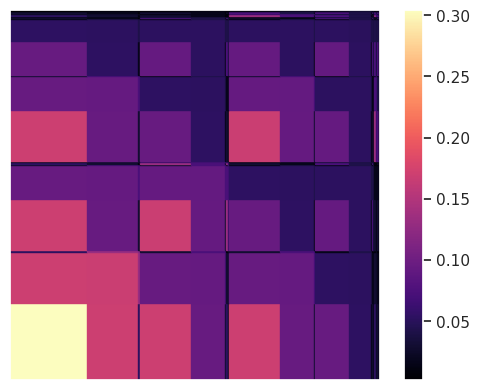

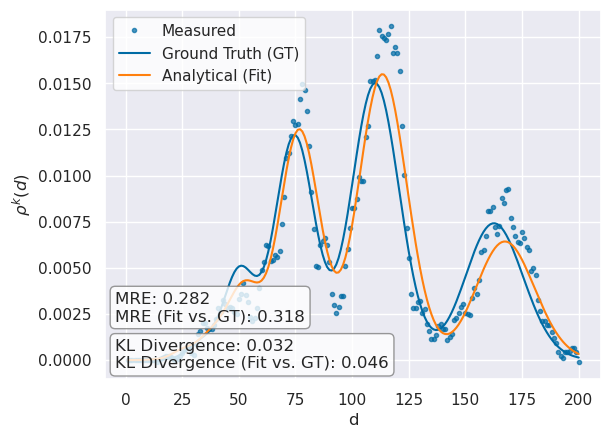

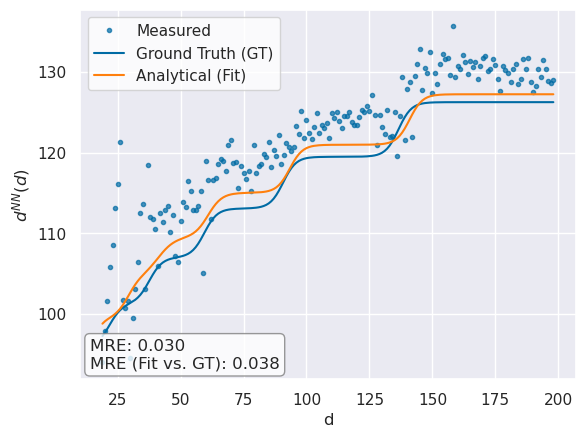

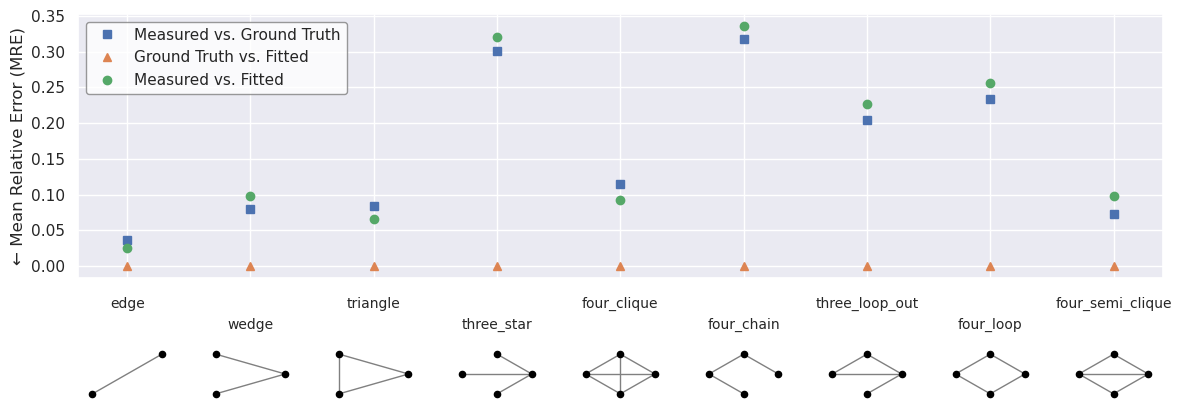

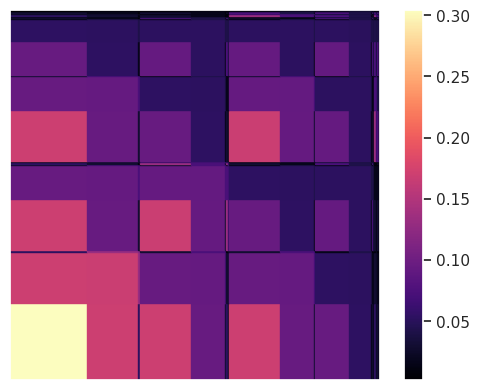

In [13]:
M = 3
K = 3
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_3_3.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_3_3_gt.pdf"
)

#### Bootstrapping

In [32]:
M = 3
K = 3
mfnf.find_P_l(m = M, k = K, one_shot=True)
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'median'
)

Energy: 5.062065382808599
KL-divergence: 0.06117321378740761
KLD augumented energy: 2.48455261000329
Gathering statistics (300 runs)...


100%|██████████| 300/300 [1:21:52<00:00, 16.37s/it]

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:00.768530
Energy = 5.01 (4.47, 5.21)
l = [0.61 (0.38, 0.67), 0.33 (0.21, 0.40), 0.07 (0.00, 0.29)]
P = [
[0.66 (0.34, 0.74), 0.37 (0.29, 0.49), 0.29 (0.06, 0.74)],

[0.37 (0.29, 0.49), 0.37 (0.16, 0.76), 0.33 (0.01, 0.74)],

[0.29 (0.06, 0.74), 0.33 (0.01, 0.74), 0.45 (0.00, 1.00)]
]


In [33]:
with open('./test_networks/synthetic_network_1k_3_3_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

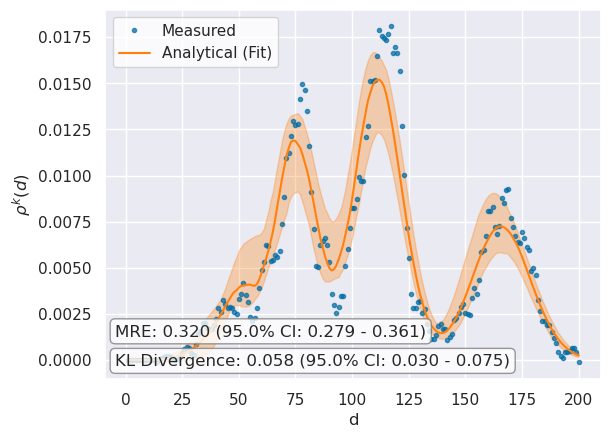

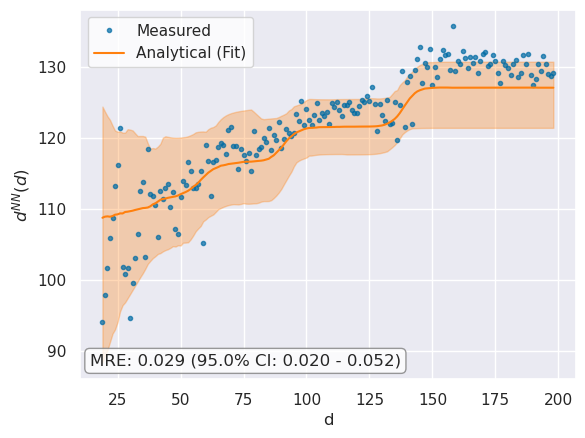

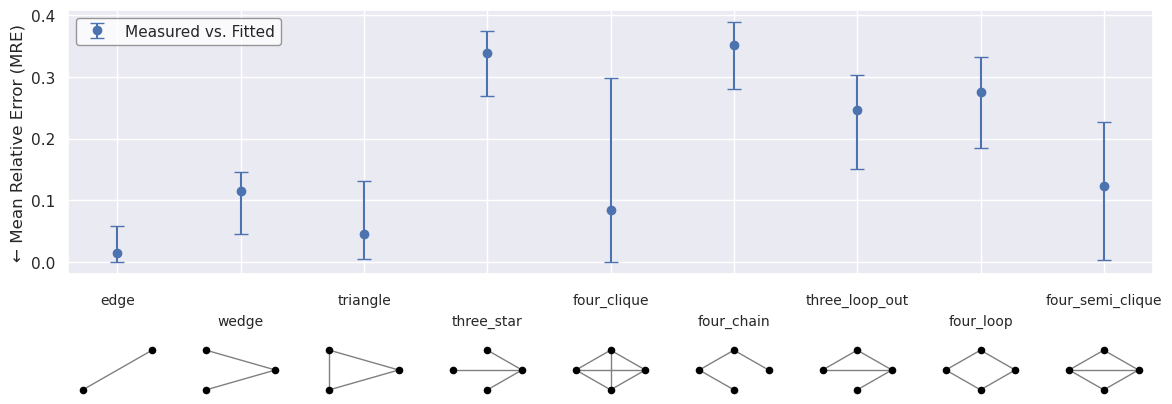

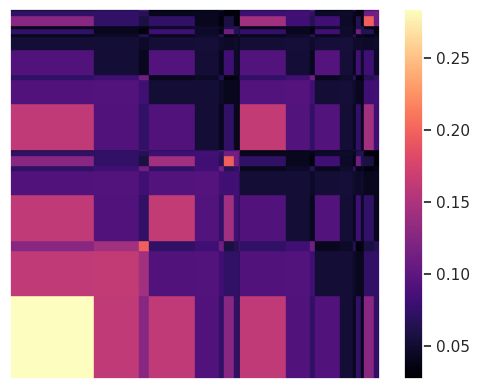

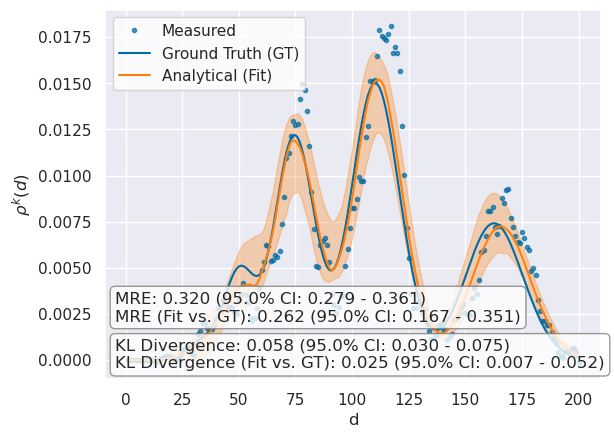

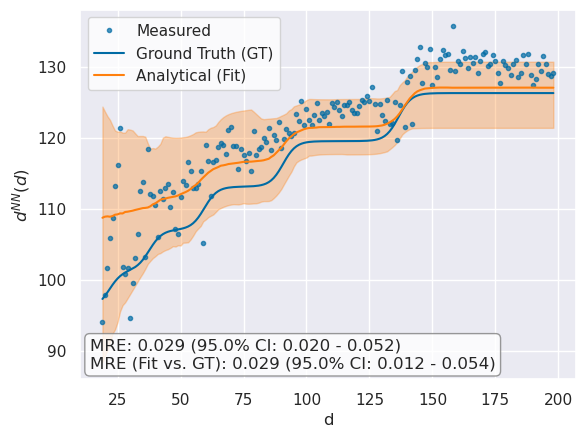

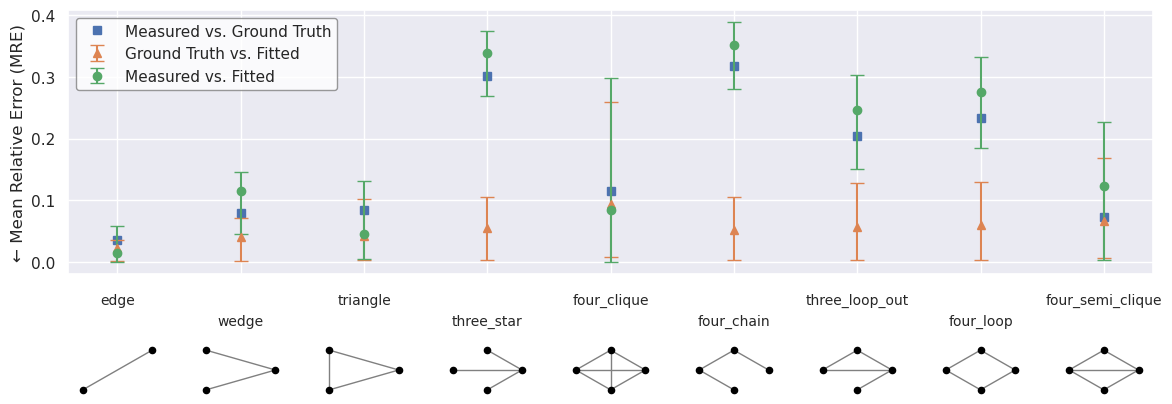

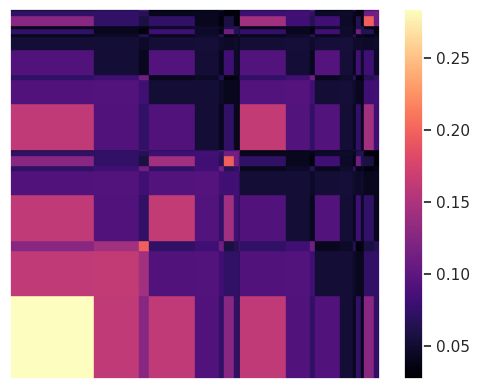

In [34]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_3_3_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_3_3_bootstrap_gt.pdf"
)

### 2-5

Energy: 4.515950406563214
KL-divergence: 0.030867053903303167
KLD augumented energy: 2.2025761279753615
[[0.77898095 0.43200437]
 [0.43200437 0.58055941]]
[0.75857873 0.24142127]


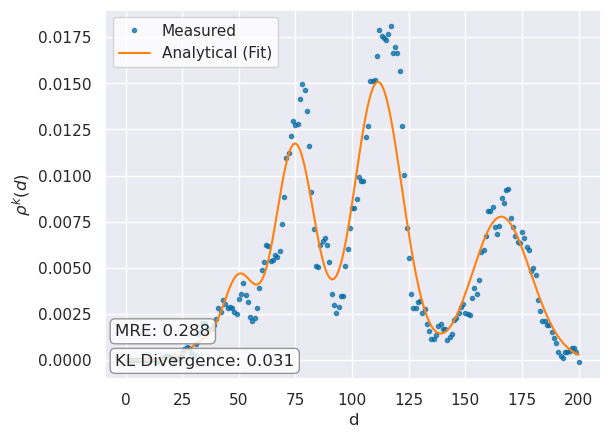

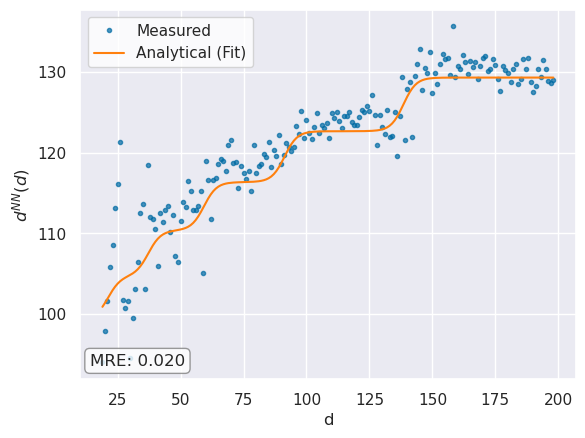

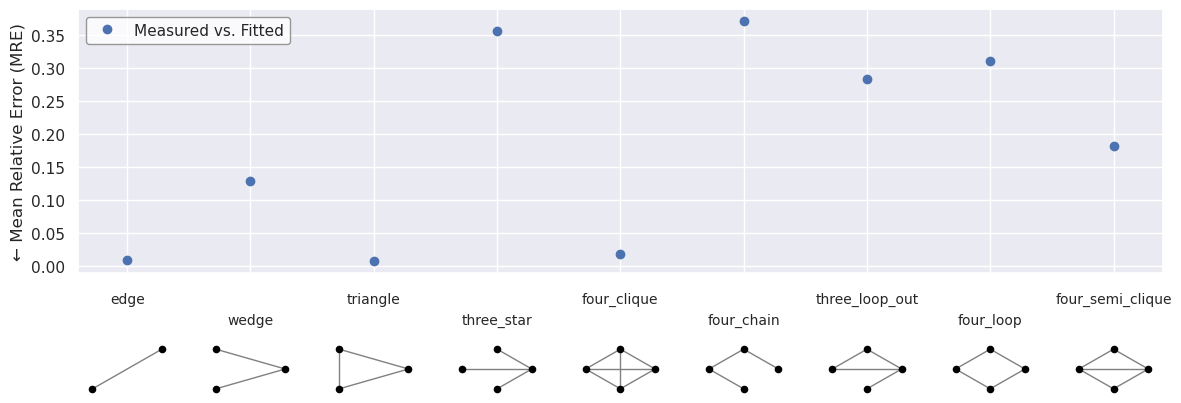

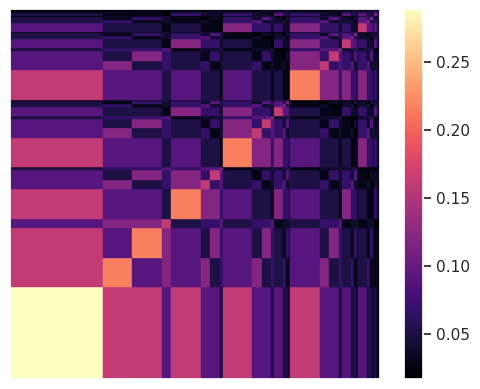

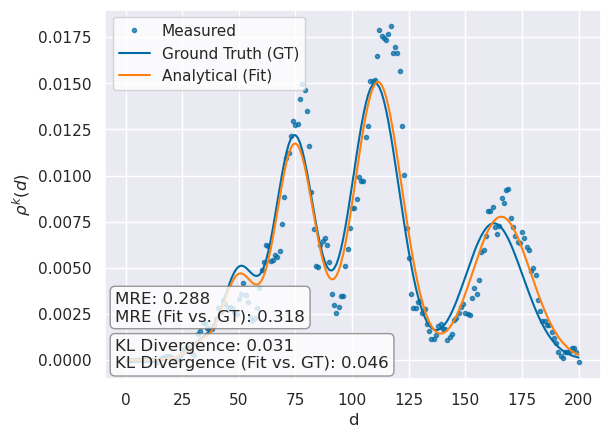

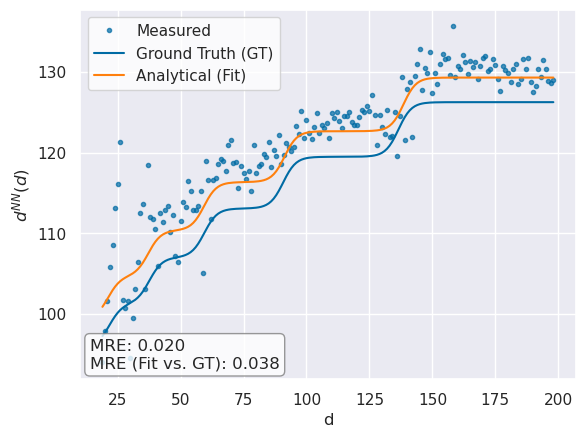

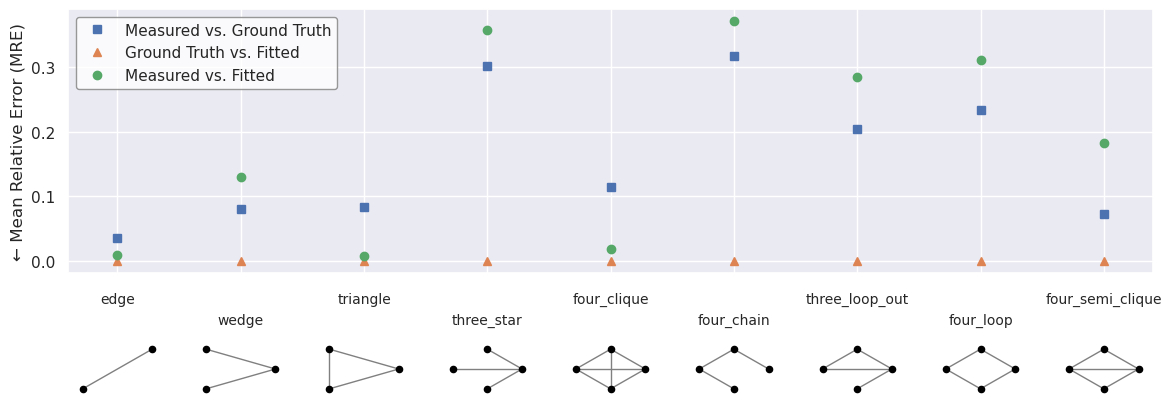

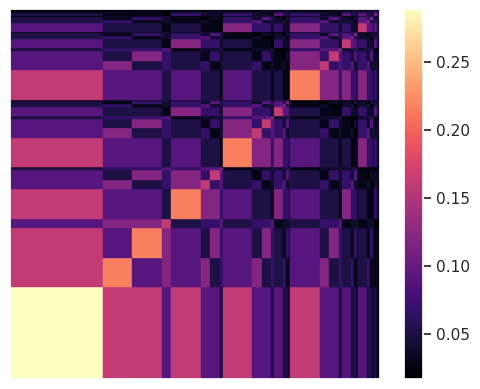

In [12]:
M = 2
K = 5
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5_gt.pdf"
)

#### Bootstrapping

In [35]:
M = 2
K = 5
mfnf.find_P_l(m = M, k = K, one_shot=True)
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'median'
)

Energy: 4.616140694913649
KL-divergence: 0.03263912632208873
KLD augumented energy: 2.3438167656439974
Gathering statistics (300 runs)...


100%|██████████| 300/300 [45:06<00:00,  9.02s/it]

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:00.713331
Energy = 4.57 (4.48, 4.77)
l = [0.75 (0.74, 0.77), 0.25 (0.23, 0.26)]
P = [
[0.78 (0.77, 0.79), 0.44 (0.42, 0.48)],

[0.44 (0.42, 0.48), 0.54 (0.44, 0.62)]
]


In [36]:
with open('./test_networks/synthetic_network_1k_2_5_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

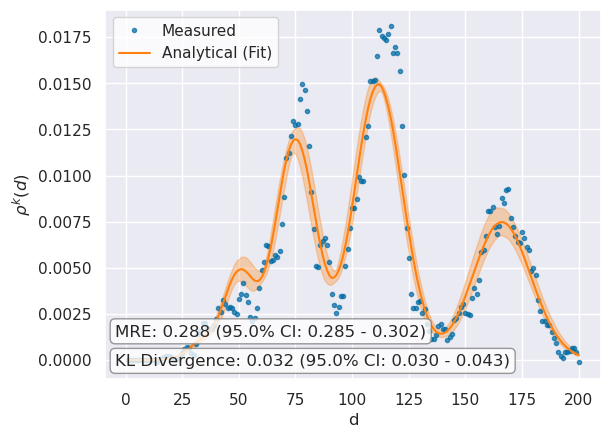

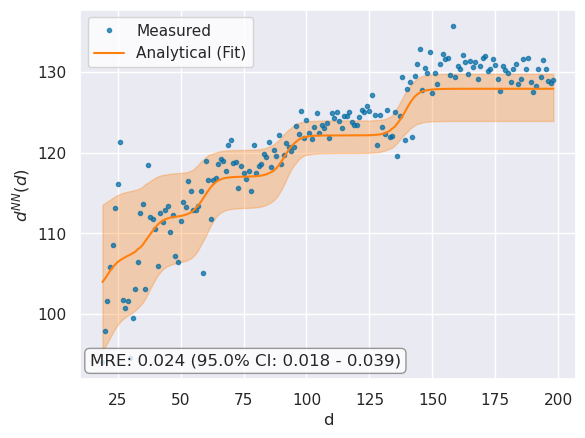

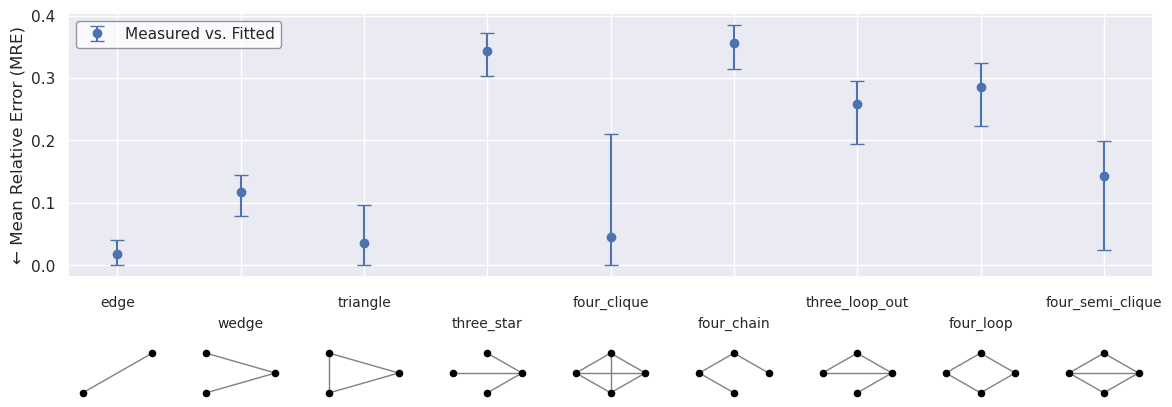

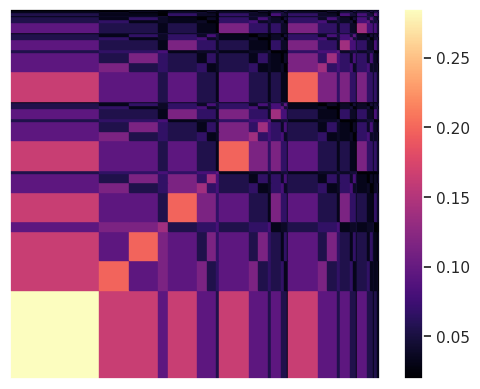

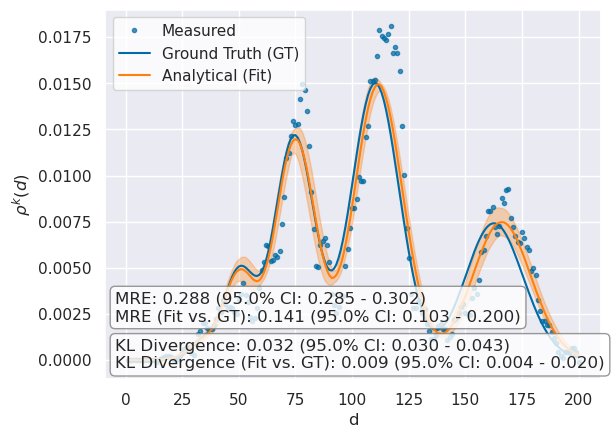

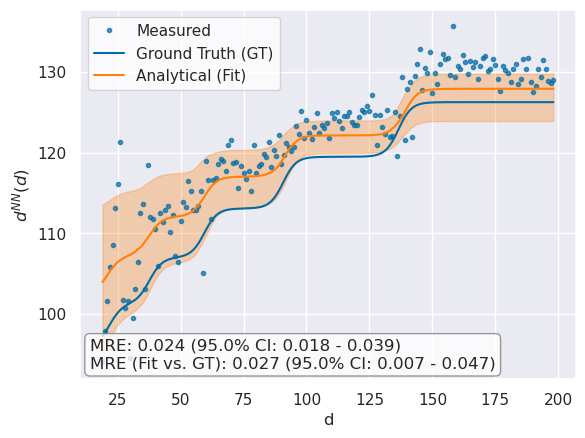

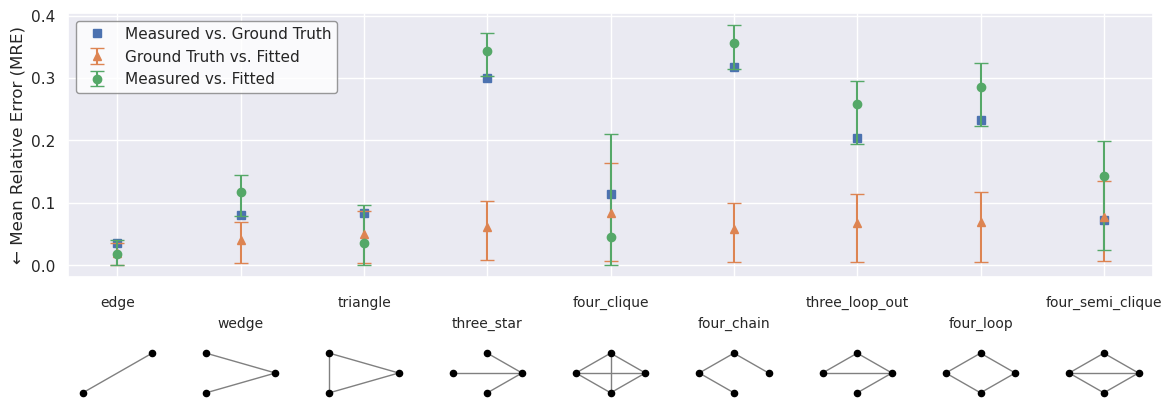

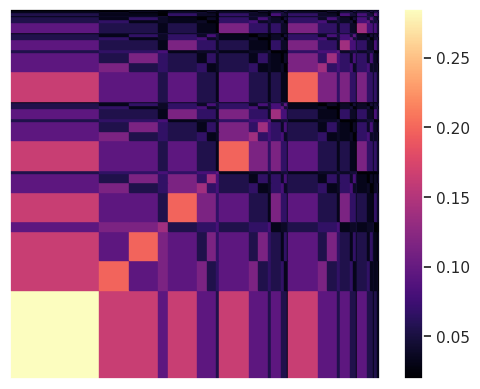

In [37]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5_bootstrap_gt.pdf"
)

---

## Variant Generation

In [38]:
M = 2
K = 5
mfnf.population_size = 500
mfnf.find_P_l(m = M, k = K, one_shot=True)

Energy: 4.481096805986554
KL-divergence: 0.030380533758286813
KLD augumented energy: 2.190041984503655


Initializing...
0.0005834102630615234
Calculating betweenness...
Done.
Calculating node positions...
Done.


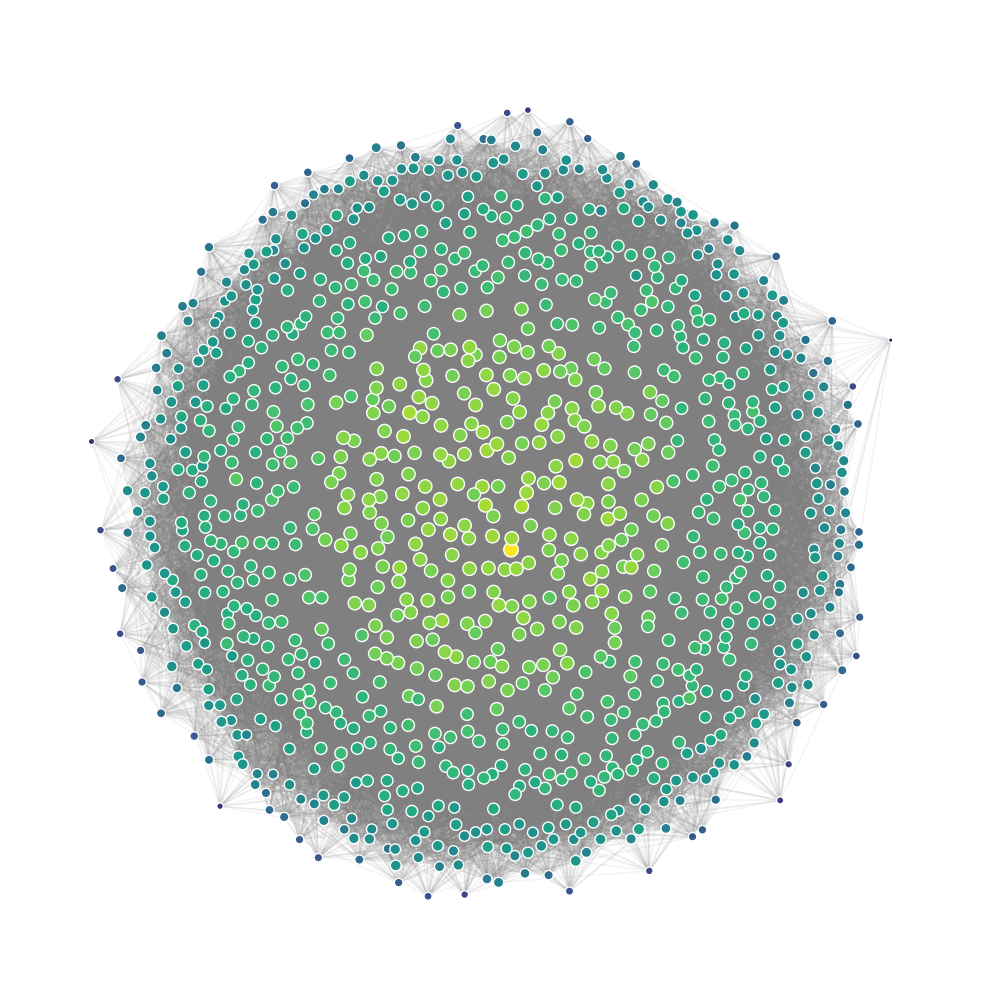

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 130.98it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


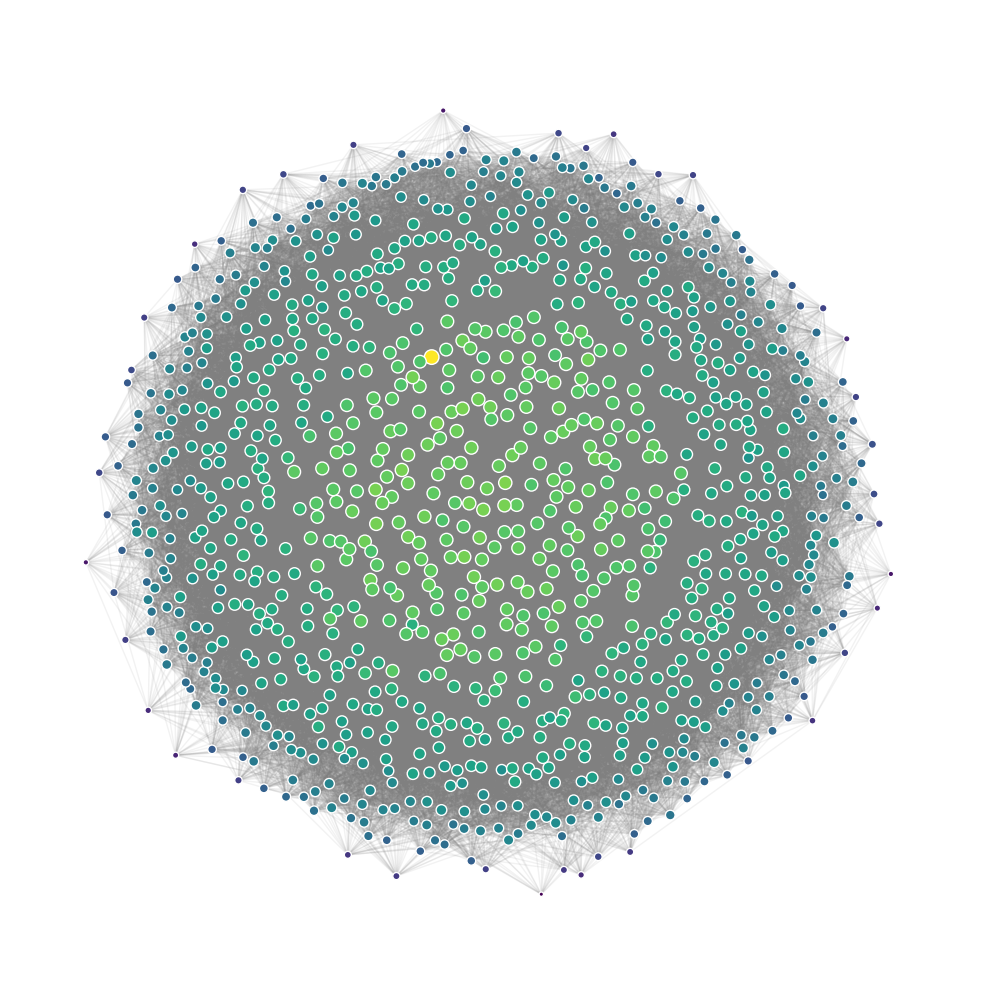

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 122.09it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


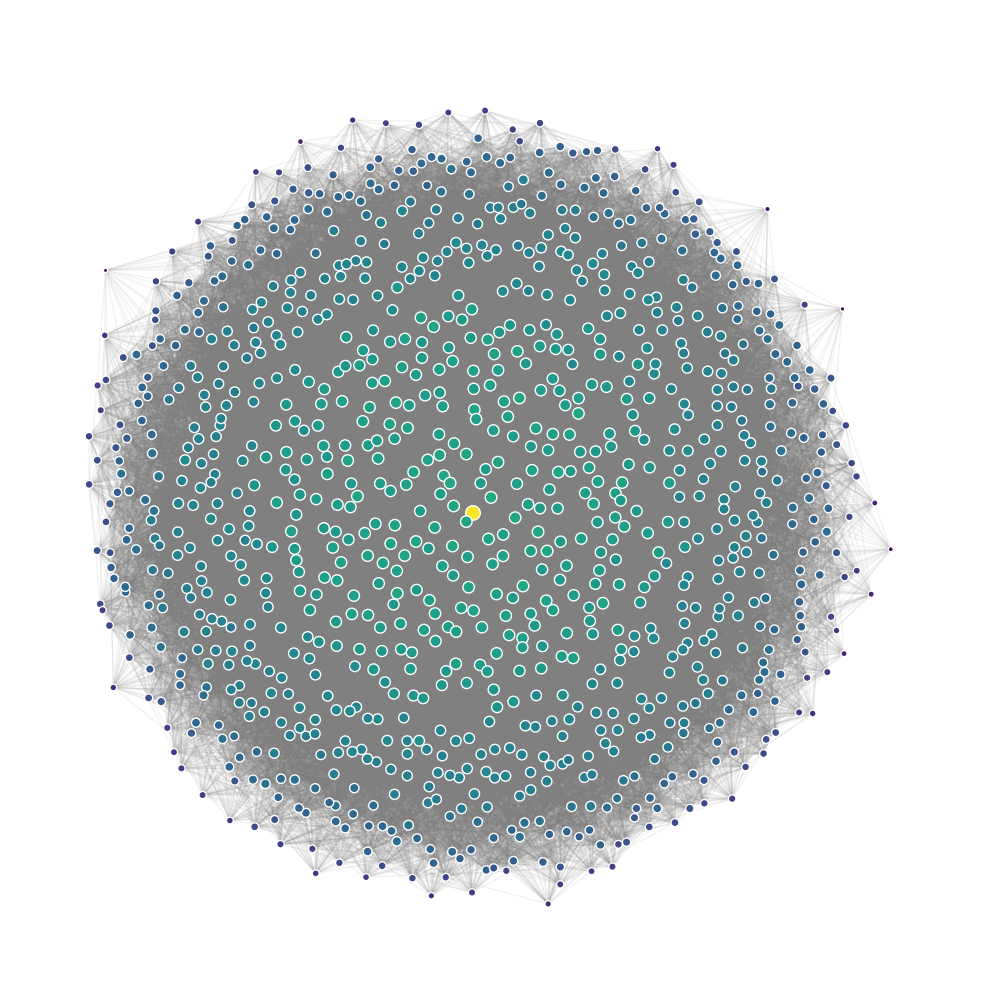

In [39]:
mfnf.generate_variants(
    number_of_variants = 2,
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/synthetic_network_1k_variants.pdf"
    },
    filename = "variant_networks/synthetic_network_1k_variants.graphml"
)